# Modularity on the Karate Club Graph
**DSC 212: Graph Theory Module**

This notebook implements recursive spectral modularity partitioning from scratch on Zachary's Karate Club network, following Newman (2006), "Modularity and community structure in networks," *PNAS* 103(23):8577-8582.


## 1.Setup: Imports and Loading the Graph

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
G=nx.karate_club_graph() 
n=G.number_of_nodes() # 34 nodes
m=G.number_of_edges() # 78 edges
nodes=list(G.nodes()) # [0,1,..,33]

## 2.Building the Adjacency, Degree and Modularity Matrices
We compute A, the degree vector k, and the modularity matrix B = A - k kᵀ / 2m. Sanity checks confirm that B is symmetric and that B·1 = 0.

In [2]:
A=nx.to_numpy_array(G,nodelist=nodes,weight=None) # karate club graph is by default a weighted graph so weigths have to be explicitly ignored  
k=A.sum(axis=1)
B=A-(np.outer(k,k)/(2*m))
assert np.allclose(B, B.T), "B is not symmetric"
assert np.allclose(B @ np.ones(n), 0), "B·1 is not zero"
print("All sanity checks passed.")

All sanity checks passed.


## 3.Spectral Bisection of a Single Community
Given a community C, we take the block B^(C), find its leading eigenpair, and split by the sign of the eigenvector entries. If the leading eigenvalues is <= 0, the community is indivisible.

In [3]:
def split_community(B, idx):
    """idx = list of node indices in the community."""
    Bc = B[np.ix_(idx,idx)]
    vals, vecs = np.linalg.eigh(Bc) # ascending order
    lam = vals[-1]
    u = vecs[:,-1]
    if lam <= 1e-10:
        return None
    c1 = [idx[i] for i in range(len(idx)) if u[i] > 0]
    c2 = [idx[i] for i in range(len(idx)) if u[i] <= 0]
    if not c1 or not c2:    # degenerate split
        return None
    return c1,c2

## 4.Recursive Bisection
We apply the bisection repeatedly. One *iteration* is defined as one split event, and a snapshot of the partition is saved after each. 

In [4]:
communities = [list(range(n))]
history = [[c[:] for c in communities]]
queue = [list(range(n))]
final=[]
while queue :
    C=queue.pop(0)
    spt = split_community(B,C)
    if spt is None :
        final.append(C)
    else :
        queue.extend(spt)
        communities = final + queue
        history.append([c[:] for c in communities])

## 5.Modularity Score After Each Split
**Extra**We compute Q for every snapshot.

Iteration 0: Q = 0.0000
Iteration 1: Q = 0.3715
Iteration 2: Q = 0.3898
Iteration 3: Q = 0.4081
Iteration 4: Q = 0.4094


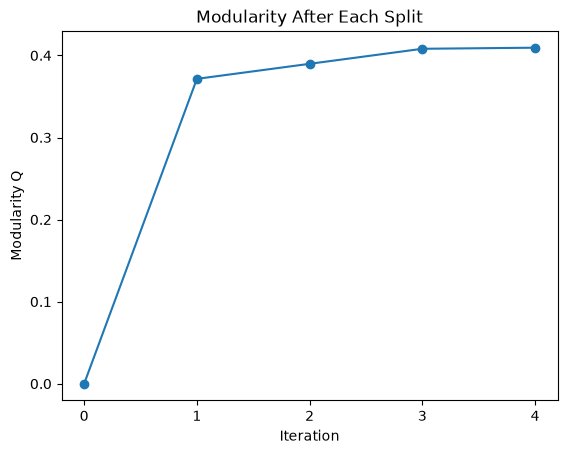

In [5]:
Q_scores=[]
for it, snap in enumerate(history):
    q=nx.community.modularity(G, [set(C) for C in snap], weight=None)
    Q_scores.append(q)
    print(f"Iteration {it}: Q = {q:.4f}")
plt.plot(range(len(Q_scores)), Q_scores, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Modularity Q")
plt.title("Modularity After Each Split")
plt.xticks(range(len(Q_scores)))
plt.show()

## 6.Visualizing the Communities at Each Iteration
All plots use one fixed spring layout. Each community has its own color and nodes are labeled by ID.

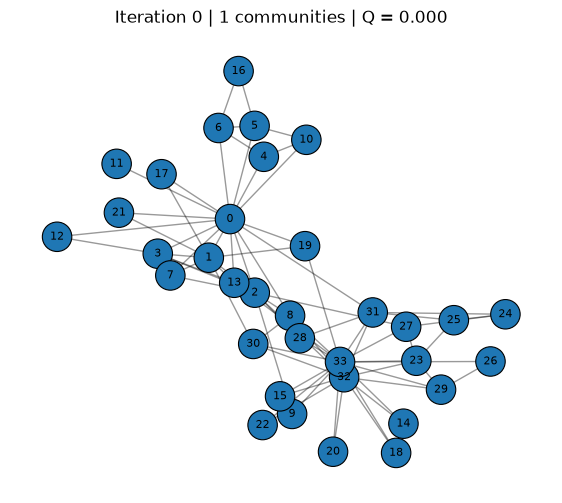

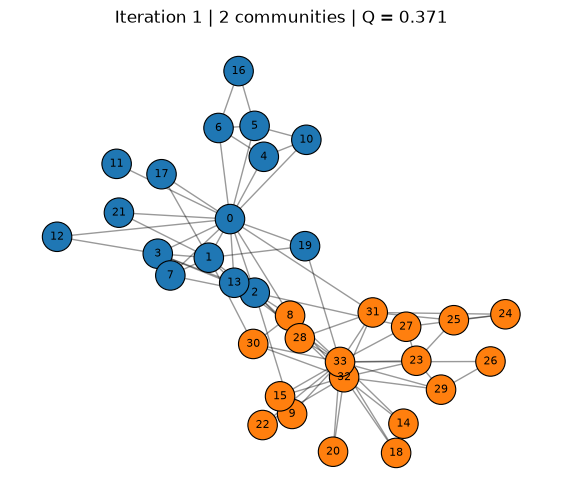

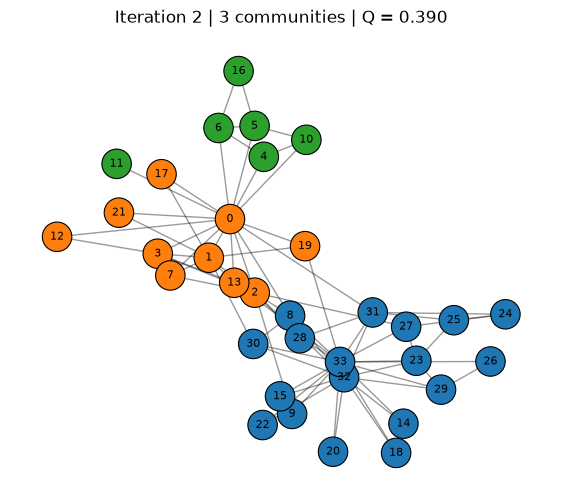

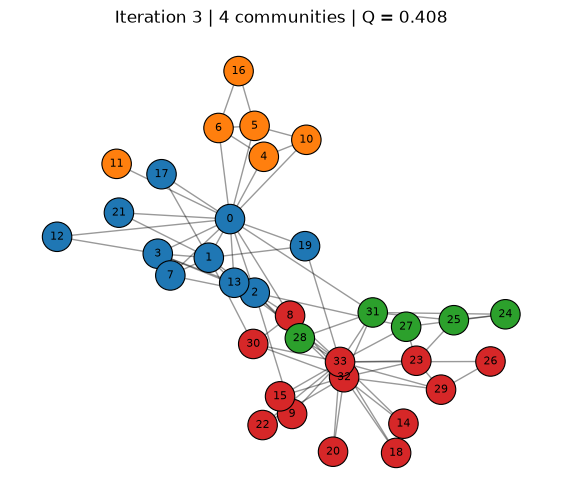

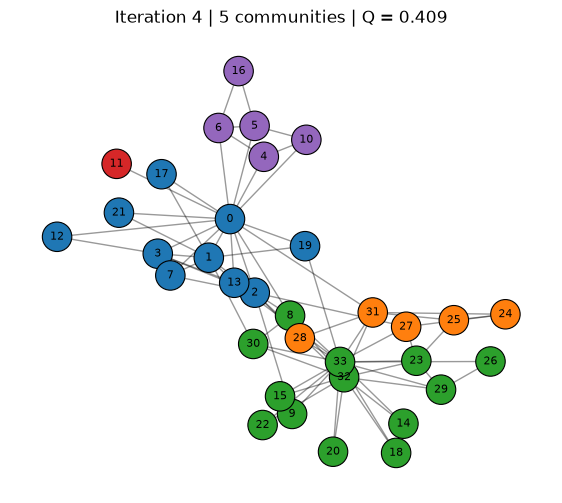

In [6]:
pos = nx.spring_layout(G, seed=42)
def plot_partition(G, partition, pos, title="", ax=None):
    """Draw G with each community in its own color."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7,6))
    cmap = plt.get_cmap("tab10")
    node_colors = {}
    for ci, C in enumerate(partition):
        for v in C:
            node_colors[v] = cmap(ci%10)
    colors = [node_colors[v] for v in G.nodes()]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4)
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=450, edgecolors="black", linewidths=0.8, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(title)
    ax.axis("off")
for it, snap in enumerate(history):
    q=nx.community.modularity(G, [set(C) for C in snap], weight=None)
    plot_partition(G, snap, pos, title=f"Iteration {it} | {len(snap)} communities | Q = {q:.3f}")
    plt.show()

## 7.Computing Node Metrics After Each Split
For each iteration we compute degree centrality, betweenness centrality, closeness centrality and clustering coefficient using NetworkX.

**Interpretation used:** Since the graph itself does not change between iterations, we compute each metric on the subgraph induced by the node's current community. Values therefore change as communities are split.

In [7]:
degree_c={}
betweenness_c={}
closeness_c={}
clustering_c={}
for it, snap in enumerate(history):
    deg, btw, clo, clu={},{},{},{}
    for C in snap:
        sub=G.subgraph(C)
        deg.update(nx.degree_centrality(sub))
        btw.update(nx.betweenness_centrality(sub))
        clo.update(nx.closeness_centrality(sub))
        clu.update(nx.clustering(sub))
    degree_c[it]=deg
    betweenness_c[it]=btw
    closeness_c[it]=clo
    clustering_c[it]=clu

## 8.Evolution of Metrics Across Iterations
### 8.1.Degree Centrality

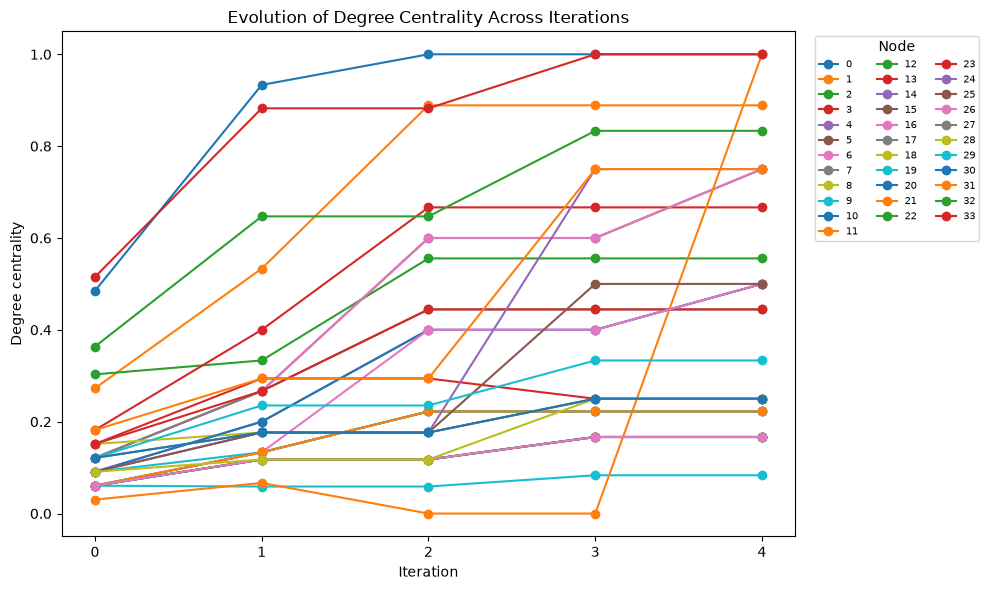

In [8]:
iters=sorted(degree_c.keys())
plt.figure(figsize=(10, 6))
for v in range(n):
    plt.plot(iters, [degree_c[it][v] for it in iters],marker="o",label=str(v))
plt.xlabel("Iteration")
plt.ylabel("Degree centrality")
plt.title('Evolution of Degree Centrality Across Iterations')
plt.xticks(iters)
plt.legend(title='Node',ncol=3, fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 8.2.Betweenness Centrality

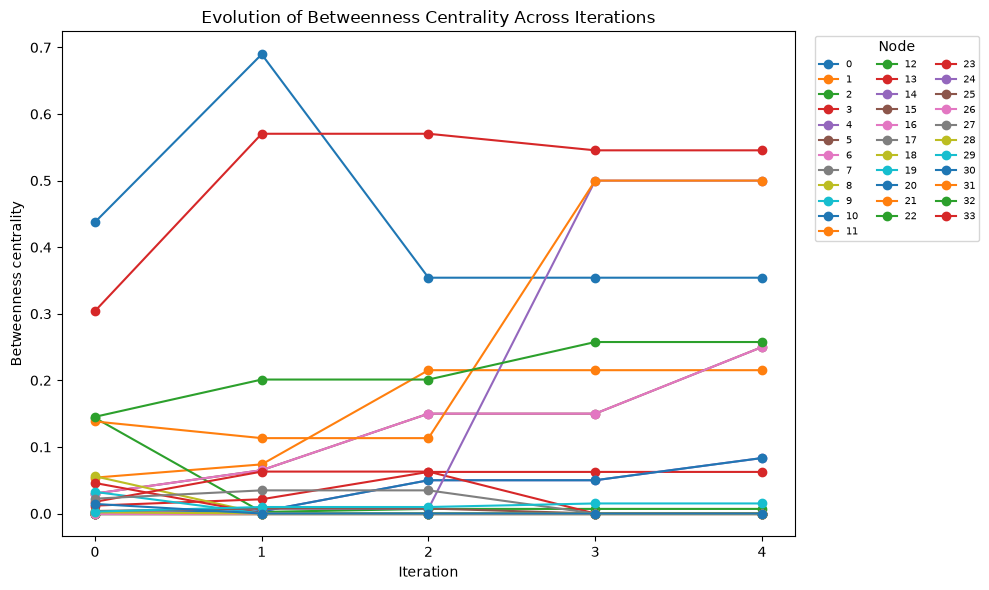

In [9]:
iters=sorted(betweenness_c.keys())
plt.figure(figsize=(10, 6))
for v in range(n):
    plt.plot(iters, [betweenness_c[it][v] for it in iters],marker="o",label=str(v))
plt.xlabel("Iteration")
plt.ylabel("Betweenness centrality")
plt.title('Evolution of Betweenness Centrality Across Iterations')
plt.xticks(iters)
plt.legend(title='Node',ncol=3, fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 8.3.Closeness Centrality

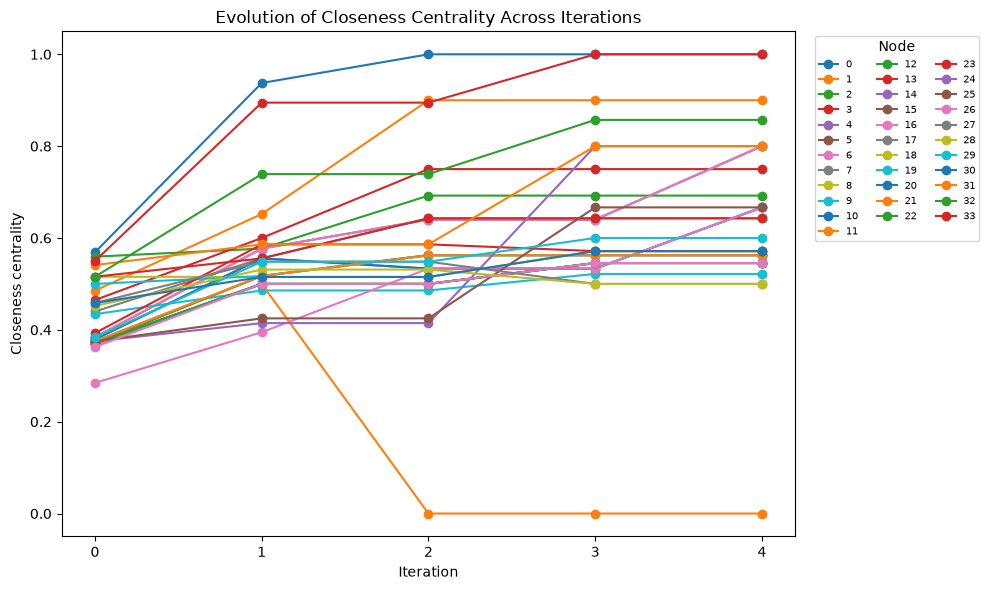

In [10]:
iters=sorted(closeness_c.keys())
plt.figure(figsize=(10, 6))
for v in range(n):
    plt.plot(iters, [closeness_c[it][v] for it in iters],marker="o",label=str(v))
plt.xlabel("Iteration")
plt.ylabel("Closeness centrality")
plt.title('Evolution of Closeness Centrality Across Iterations')
plt.xticks(iters)
plt.legend(title='Node',ncol=3, fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 8.4.Clustering Coefficient

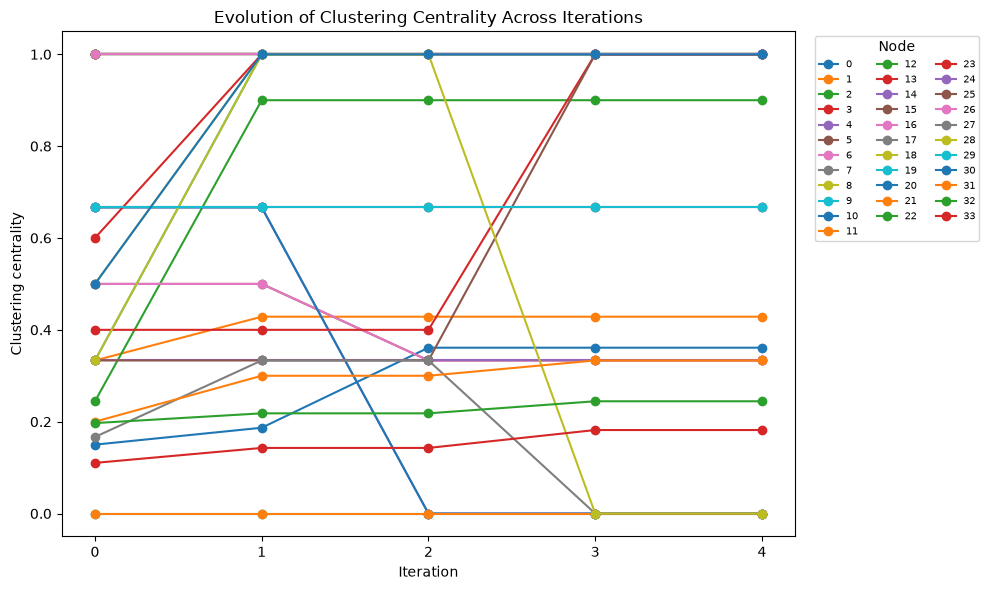

In [11]:
iters=sorted(clustering_c.keys())
plt.figure(figsize=(10, 6))
for v in range(n):
    plt.plot(iters, [clustering_c[it][v] for it in iters],marker="o",label=str(v))
plt.xlabel("Iteration")
plt.ylabel("Clustering centrality")
plt.title('Evolution of Clustering Centrality Across Iterations')
plt.xticks(iters)
plt.legend(title='Node',ncol=3, fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 9.Comparison with the Real Club Split
**Extra**We compare the first bisection with the 'club' attribute (Mr. Hi vs. Officer) and count misclassified nodes.

In [12]:
first_split=history[1]
group_a, group_b=set(first_split[0]), set(first_split[1])
hi={v for v in G.nodes() if G.nodes[v]['club']=='Mr. Hi'}
officer={v for v in G.nodes() if G.nodes[v]['club']=='Officer'}
mis_1=(group_a - hi) | (group_b - officer)
mis_2=(group_a - officer) | (group_b - hi)
misclassified = mis_1 if len(mis_1)<=len(mis_2) else mis_2
print('Group A:', sorted(group_a))
print('Group B:', sorted(group_b))
print('Misclassified nodes:', sorted(misclassified))
print('Number misclassified:', len(misclassified), 'out of', n)
print('Accuracy:', round(1-len(misclassified)/n, 3))

Group A: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group B: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Misclassified nodes: [8]
Number misclassified: 1 out of 34
Accuracy: 0.971


## 10. Discussions
- **Q1) Which nodes remain central across splits?**  
    Nodes **0** (Mr. Hi) and **33** (the Officer) are the most central nodes throughout. On the whole graph they have the highest degree centrality (33: about 0.515, 0: about 0.485) and the highest betweenness centrality (0.304 and 0.438 for 33 and 0), and both are in the top group for closeness (0.55 and 0.569). After each split they remain the top-ranked nodes inside their own communities: degree centrality reaches 1.0 for node 0 at iteration 2 and for node 33 at iteration 3, and closeness reaches 1.0 for both, meaning each is directly linked to every other member of its community.  
    Within their factions, node **32** (degree 0.364 -> 0.647 -> 0.833, betweenness 0.145 -> 0.201 -> 0.258) and node **1** (degree 0.273 -> 0.533 -> 0.889) are the next most central. Node **2** is central only in the whole graph (degree 0.303, betweenness 0.144). After the first split its betweenness collapses to 0.002, because half its neighbours (8, 9, 27, 28, 32) lie in the other faction, so it was a bridge between factions, not a hub within one. Node **31** has a similar pattern: moderate whole-graph betweenness (0.138), but it becomes a key broker (0.5) in the small community {24, 25, 27, 28, 31}. 
- **Q2) How does community structure influence each metric?**  
    **Degree centrality:** rises for almost every node. Cross-community edges are removed, but the normaliser |C| - 1 shrinks faster. Hubs show this clearly (node 0: 0.485 -> 0.933 -> 1.0). A node with many cross-community links gains little (node 2: 0.303 -> 0.333).  
    **Betweenness centrality:** not monotonic. It first rises for the main hubs (node 0: 0.438 -> 0.690, node 33: 0.304 -> 0.570), since inside a faction almost every shortest path passes through its hub, then falls as communities shrink (node 0: 0.354 at iteration 2). Bridge nodes lose their role completely (node 2: 0.144 -> 0.002, node 8: 0.056 -> 0).  
    **Closeness centrality:** rises for nearly all nodes because distances inside a smaller, denser community are shorter. For example, node 16 had the lowest whole-graph closeness (0.284), and the hubs reach 1.0. The exception is node 11, whose closeness is 0.0 once it is isolated.  
    **Clustering coefficient:** hubs have low clustering in the whole graph (node 0: 0.15, node 33: 0.11, node 32: 0.197) because their neighbours are spread across different groups. Clustering rises when cross-community neighbours are removed (node 0: 0.15 -> 0.361, node 2: 0.244 -> 0.9, node 8: 0.5 -> 1.0). Node 11 drops to 0 as a singleton (NetworkX convention).
    Overall, whole-graph values are fixed, but community-level values show who is central *locally* inside a faction. Values are normalised within each subgraph, so they are not directly comparable across iterations.

## Refrences
Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577-8582.  
Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452-473.